Proyecto PAPIME PE110923 DESARROLLO DE UN LABORATORIO DE ROBOTICA REMOTO PARA REALIZAR PRACTICAS DE PROGRAMACION DE ALGORITMOS DE PLANEACION Y DE NAVEGACION EN BANCOS DE PRUEBA FISICOS

# <span style="color:rgb(213,80,0)">Este material fue desarrollado con el apoyo del PAPIME PE110923 de la UNAM</span>

## Academia de Robótica

## Autores
- M.I. Erik Peña Medina
- Dr. Víctor Javier Gonzáles Villela

# <span style="color:rgb(213,80,0)">Práctica 2 Programación de un robot para la realización de tareas de manipulación de objetos.</span>

Semestre 2027\-1

Montiel García Germán

Hipótesis

Mediente el uso de la libreria del robot Dofbot es posible capturar una serie de poses las cuales permitena programar a un robot Dofbot para realizar la manipulación simple de un objeto.

## Objetivo

Generar un programa que permita capturar las posituras de un robot Dofbot para que este realice una tarea de manipulación de objetos simples, y posteriormente utilizar esa información para programar al robot para que repita dicha tarea.

- Que el alumno aprenda las bases del Aprendizaje por Demostración en robots.
- Que el alumno programe una secuencia de posturas de un robot para que este realice una tarea de manipulación de objetos simples.

Contribución al perfil del egresado

La siguiente práctica contribuye en los siguientes puntos al perfil del egresado:

Aptitudes y habilidades

- Para modelar, simular e interpretar el comportamiento de los sistemas mecatrónicos.
- Para desarrollar, operar y mantener procesos productivos que impliquen la transformación de materia, energía e información.
- Para diseñar, construir, operar y mantener los sistemas mecatrónicos y sus componentes.

Actitudes

- Ser creativo e innovador.
- Tener confianza en su preparación académica.
- Comprometido con su actualización, superación y competencia profesional.

De tipo social

- Promover el cambio en la mentalidad frente a la competitividad internacional.

## Rúbrica de evaluación

La evaluación de la práctica contará de los siguientes puntos:

| **Elemento** <br>  | **Porcentaje** <br>   |
| :-: | :-: |
| ***Previo*** <br>  | 25% <br>   |
| **Desarrollo** <br>  | 25% <br>   |
| **Resultado** <br>  | 25% <br>   |
| **Conclusiones** <br>  | 25% <br>   |

Los siguientes elementos se evaluaran con base en los siguientes criterios:

| **Elemento** <br>  | **Malo** <br>  | **Regular** <br>  | **Bueno** <br>  | **Muy bueno** <br>   |
| :-- | :-- | :-- | :-: | :-: |
| ***Previo*** <br>  | El previo no contiene los elemtos solocitados (0%) <br>  | El previo contiene parcialmente la infomración solocitada (10%) <br>  | El previo contiene la infomración solocitada sin referencias (20%) <br>  | El previo contiene la información solicitada con referencias (25%) <br>   |
| **Desarrollo** <br>  | El desarrollo de la práctica no fue realizada (0%) <br>  | El desarrollo de la práctica fue pacialmente realizado (10%) <br>  | La práctica fue realizada pero no fue realizada correctamente (20%) <br>  | La práctica fue realizada en su totalidad correctamente (25%) <br>   |
| **Resultado** <br>  | No se entregarón los resultados de la práctica (0%) <br>  | Se entregaron pracialmente los resultados (10%) <br>  | Se entregaron los resultados sin descripción (20%) <br>  | Se entregaron los resultados de la práctica y son interpetrables(25%) <br>   |
| **Conclusiones** <br>  | No se entragaron conclusiones (0%) <br>  | Las conclusciones no están relacionadas  <br>   |

# <span style="color:rgb(213,80,0)">Previo de la Práctica 2</span>

Se le solicita al alumno investigar y colocar la sigueinte información en esta sección:

Bases del Aprendizaje por Demostración (*Learning from Demonstration*, LfD)

El Aprendizaje por Demostración (LfD) —también conocido como *programación por demostración* o *imitación*— es un paradigma en el que un robot aprende a ejecutar una tarea observando o recibiendo ejemplos guiados por un demostrador humano, en lugar de requerir que cada movimiento sea programado explícitamente desde cero mediante código o trayectorias rígidas.Modalidades de captura de demostraciones

- **Guiado cinestésico:** El operador toma físicamente el brazo robótico, habitualmente en modo de compensación de gravedad o baja rigidez y lo guía a través de las posturas y trayectorias deseadas mientras el sistema registra ángulos articulares, poses o fuerzas.
- **Teleoperación:** El humano controla el robot de forma remota mediante *joysticks*, dispositivos hápticos, controladores de realidad virtual/mixta o interfaces maestras, registrando las señales de comando y el estado del robot.
- **Observación externa:** El sistema captura la tarea mediante cámaras, sensores de movimiento o seguimiento de objetos para inferir trayectorias y acciones relevantes.
-

La estructura mecánica determina el alcance, la rigidez, la capacidad de carga y la precisión con la que un robot puede ejecutar movimientos en su entorno.

Componentes estructurales fundamentales

- **Base y eslabones (*****links*****):** La base ancla o soporta al manipulador respecto al marco de referencia inercial; los eslabones son los cuerpos rígidos que conectan las articulaciones y definen las longitudes geométricas del sistema.
- **Articulaciones (*****joints*****):** Permiten el movimiento relativo entre eslabones consecutivos. Las más comunes son las  **rotacionales** (giro alrededor de un eje, con ángulo articular $q_i$ ) y las  **prismáticas** (desplazamiento lineal a lo largo de un eje).
- **Muñeca y efector final (*****end\-effector*****):** La muñeca suele aportar orientación adicional , mientras que el efector final (*gripper*, pinza paralela, ventosa o herramienta) interactúa directamente con el objeto.
- **Transmisiones y actuadores:** Motores (DC, *brushless*, *servomotors* o actuadores neumáticos/lineales) acoplados mediante reductores de engranes, correas, husillos o cables que entregan par o fuerza y reducen velocidad.

## Desarrollo de la práctica

El desarrollo de la práctica se divide en las siguientes partes.

1. Generar el progrma para la captura de las posturas del robot.


In [1]:
%% 1. Calibración de cero en grados (0° = erguido natural del URDF)
q_cero = [0, 0, 0, 0, 0];


%% 2. Posturas [q1, q2, q3, q4, q5] en grados (5 articulaciones móviles)
% Recuerda mantener siempre las comas ',' entre ángulos
q = [
    0,   0,   0,   0,   0;  % q(1): Totalmente erguido (inicio)
    -25,  15,  25,  20,   0;  % q(2): Girar cintura y pre-aproximar
    -25,  30,  45,  35,   0;  % q(3): Bajar sobre objeto
    -25,  30,  45,  35,  30;  % q(4): Orientar/accionar mano en agarre
    -25,  15,  25,  20,  30;  % q(5): Elevar objeto
    25,  15,  25,  20,  30;  % q(6): Girar hacia zona de colocación
    25,  30,  45,  35,  30;  % q(7): Bajar en zona de colocación
    25,  30,  45,  35,   0;  % q(8): Liberar / regresar mano
    0,   0,   0,   0,   0   % q(9): Regreso a totalmente erguido
    ];


n = size(q, 1);          % Número de posturas
paso_tiempo = 3;         % Segundos entre posturas


%% 3. Conversión a radianes
theta = deg2rad(q - q_cero);


%% 4. Vectores [tiempo, angulo] para Simulink (5 juntas móviles)
t_col = (0 : paso_tiempo : paso_tiempo*(n-1))';


theta1_tiempo = [t_col, theta(:,1)];
theta2_tiempo = [t_col, theta(:,2)];
theta3_tiempo = [t_col, theta(:,3)];
theta4_tiempo = [t_col, theta(:,4)];
theta5_tiempo = [t_col, theta(:,5)];


disp(['Listo: ', num2str(n), ' posturas generadas hasta t = ', num2str(t_col(end)), ' s.']);


1. Realizar el entrenamiento del robot para que manipule un objeto.
    1. A partir de las posturas capturadas se estructuró la secuencia de manipulación: giro de la base (theta1) hacia la zona de toma, inclinación coordinada de hombro, codo y muñeca (theta2, theta3, theta4) para aproximar y descender sobre el objeto, giro/accionamiento terminal (theta5), elevación, traslado angular hacia la zona de colocación, descenso, liberación y retorno a la postura erguida en $t=24\;\textrm{s}$
2. Verificar que el robot realice la tarea programada.
    1. Se ejecutó la simulación completa de $24\;\textrm{s}$ y se inspeccionaron las respuestas articulares y dinámicas mediante Scopes para comprobar que el manipulador complete el ciclo y regrese a su condición inicial (0 rad, 0 rad/s, par y potencia cercanos a cero al final del recorrido).
    2. La verificación permitió identificar picos transitorios en el par y en la potencia eléctrica/mecánica en los instantes de transición de $3\;\textrm{s}$, asociados a los cambios escalonados de velocidad angular (Omega1–Omega5).

## Resultados

En esta sección se deben de colocar los resultados del desarrollo de la práctrica, los resultados deben seguir el siguiente formato:Gráficas

Las gráficas deben contener el siguiente formato:

- Las gráficas deben ser claras,
- Contar con un título en la parte inferior a esta, el cual debe describirla,
- En caso de ser una gráfica de resultados los ejes deben llevar una leyenda que indique la relación que se presenta.

#### **Posición**

<p style="text-align:left">
   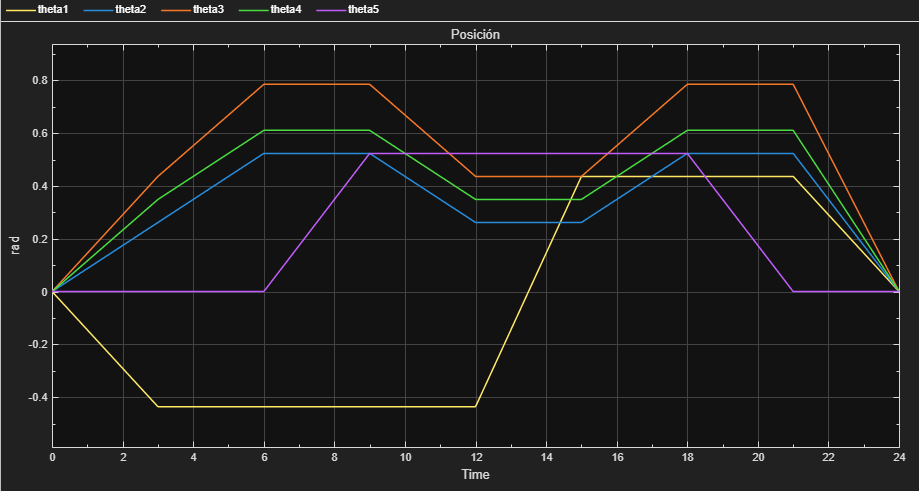
</p>

#### ***Velocidad***

<p style="text-align:left">
   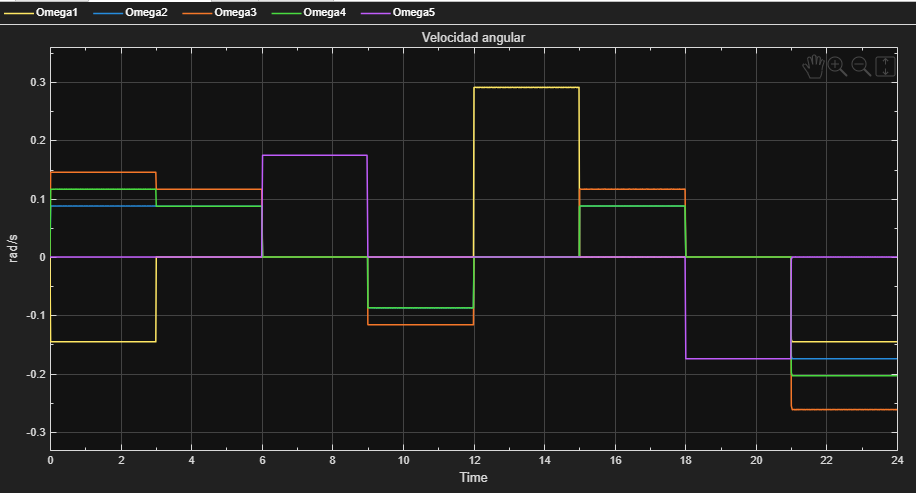
</p>

#### **Par**

<p style="text-align:left">
   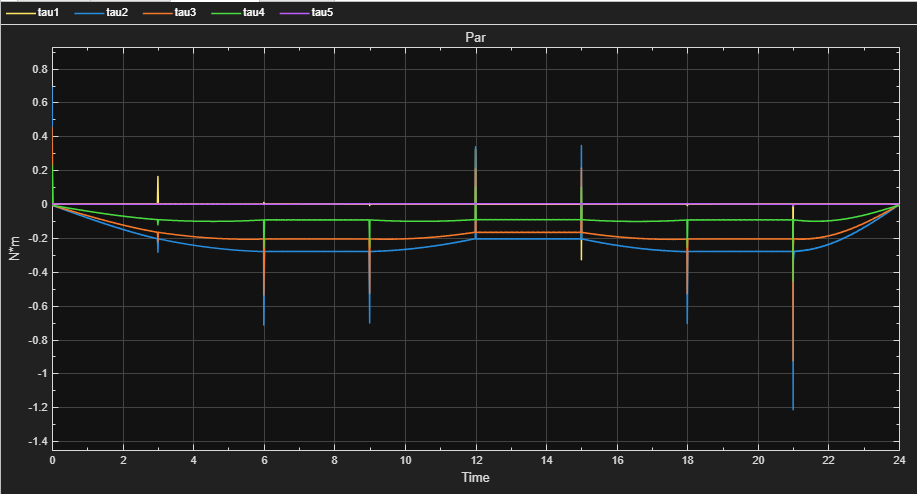
</p>

#### **Potencia**
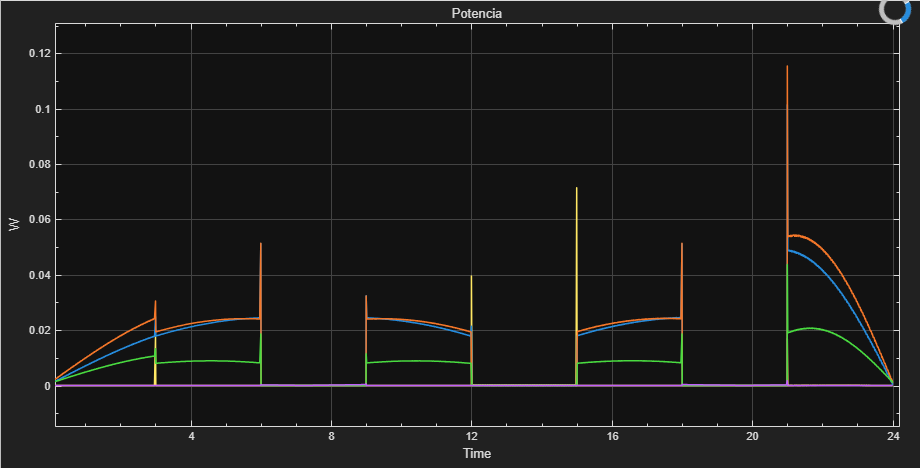

## Conclusiones

Se cumplió el objetivo general de generar un programa para capturar las posturas del manipulador Dofbot y emplear dicha información en la programación de una tarea de manipulación de objetos simples, logrando que el robot ejecute una secuencia ordenada y repetible desde su postura erguida inicial hasta el retorno al estado de partida.

Se asimilaron las bases del Aprendizaje por Demostración (LfD) al comprender cómo el registro de posturas clave y trayectorias facilita reproducir tareas sin codificar cada movimiento desde cero, así como la importancia de definir referencias articulares claras (como el cero erguido y los límites de cada junta) para evitar errores de interpretación entre la demostración y la ejecución.

Se logró programar y verificar una secuencia de posturas articulares para manipular un objeto simple, comprobando mediante las señales de posición, velocidad angular, par y potencia que la articulación de posturas en intervalos definidos permite completar la tarea, aunque el uso de trayectorias suavizadas o interpoladas constituye un siguiente paso recomendable para reducir picos transitorios en el par y la potencia durante los cambios de movimiento.

### Bibliografía

\[1\]The MathWorks, Inc., *Simscape Multibody Documentation*, Natick, MA, USA: MathWorks. \[Online\]. Available: [https://www.mathworks.com/help/sm/](https://www.mathworks.com/help/sm/)

\[2\] ROS Wiki, "URDF (Unified Robot Description Format) XML Specification," Open Source Robotics Foundation. \[Online\]. Available: [http://wiki.ros.org/urdf](http://wiki.ros.org/urdf)